In [1]:

import pandas as pd 
from matplotlib import pyplot as plt
import seaborn as sns
import numpy as np
from scipy import stats as st
from statsmodels.stats.proportion import proportions_ztest
from statsmodels.stats.weightstats import ztest


### Analasis exploratorio de datos

In [2]:

clients=pd.read_csv("/datasets/telecom_clients.csv")
clients.head()


,user_id,tariff_plan,date_start
0,166713,A,2019-08-15
1,166901,A,2019-08-23
2,168527,A,2019-10-29
3,167097,A,2019-09-01
4,168193,A,2019-10-16


In [3]:
clients.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 732 entries, 0 to 731
Data columns (total 3 columns):
 #   Column       Non-Null Count  Dtype 
---  ------       --------------  ----- 
 0   user_id      732 non-null    int64 
 1   tariff_plan  732 non-null    object
 2   date_start   732 non-null    object
dtypes: int64(1), object(2)
memory usage: 17.3+ KB


In [4]:
clients.duplicated().sum()

0

Tabla clientes sin duplicados 

In [5]:
calls=pd.read_csv("/datasets/telecom_dataset_us.csv")
calls.head()





,user_id,date,direction,internal,operator_id,is_missed_call,calls_count,call_duration,total_call_duration
0,166377,2019-08-04 00:00:00+03:00,in,False,NaN,True,2,0,4
1,166377,2019-08-05 00:00:00+03:00,out,True,880022.0,True,3,0,5
2,166377,2019-08-05 00:00:00+03:00,out,True,880020.0,True,1,0,1
3,166377,2019-08-05 00:00:00+03:00,out,True,880020.0,False,1,10,18
4,166377,2019-08-05 00:00:00+03:00,out,False,880022.0,True,3,0,25


In [6]:
calls.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 53902 entries, 0 to 53901
Data columns (total 9 columns):
 #   Column               Non-Null Count  Dtype  
---  ------               --------------  -----  
 0   user_id              53902 non-null  int64  
 1   date                 53902 non-null  object 
 2   direction            53902 non-null  object 
 3   internal             53785 non-null  object 
 4   operator_id          45730 non-null  float64
 5   is_missed_call       53902 non-null  bool   
 6   calls_count          53902 non-null  int64  
 7   call_duration        53902 non-null  int64  
 8   total_call_duration  53902 non-null  int64  
dtypes: bool(1), float64(1), int64(4), object(3)
memory usage: 3.3+ MB


In [7]:
calls.duplicated().sum()

4900

In [8]:
calls.drop_duplicates(inplace=True)
calls.info()

<class 'pandas.core.frame.DataFrame'>
Int64Index: 49002 entries, 0 to 53901
Data columns (total 9 columns):
 #   Column               Non-Null Count  Dtype  
---  ------               --------------  -----  
 0   user_id              49002 non-null  int64  
 1   date                 49002 non-null  object 
 2   direction            49002 non-null  object 
 3   internal             48892 non-null  object 
 4   operator_id          41546 non-null  float64
 5   is_missed_call       49002 non-null  bool   
 6   calls_count          49002 non-null  int64  
 7   call_duration        49002 non-null  int64  
 8   total_call_duration  49002 non-null  int64  
dtypes: bool(1), float64(1), int64(4), object(3)
memory usage: 3.4+ MB


Elimandando filas duplicadas de la tabla calls 

In [9]:
calls['date'] = pd.to_datetime(calls['date'], format='%Y-%m-%d %H:%M:%S%z')

In [10]:
calls.head(10)


,user_id,date,direction,internal,operator_id,is_missed_call,calls_count,call_duration,total_call_duration
0,166377,2019-08-04 00:00:00+03:00,in,False,NaN,True,2,0,4
1,166377,2019-08-05 00:00:00+03:00,out,True,880022.0,True,3,0,5
2,166377,2019-08-05 00:00:00+03:00,out,True,880020.0,True,1,0,1
3,166377,2019-08-05 00:00:00+03:00,out,True,880020.0,False,1,10,18
4,166377,2019-08-05 00:00:00+03:00,out,False,880022.0,True,3,0,25
5,166377,2019-08-05 00:00:00+03:00,out,False,880020.0,False,2,3,29
6,166377,2019-08-05 00:00:00+03:00,out,False,880020.0,True,8,0,50
7,166377,2019-08-05 00:00:00+03:00,in,False,NaN,True,6,0,35
9,166377,2019-08-06 00:00:00+03:00,in,False,NaN,True,4,0,62
10,166377,2019-08-06 00:00:00+03:00,out,False,881278.0,True,3,0,29


In [11]:
calls[calls['operator_id'].isnull()]

,user_id,date,direction,internal,operator_id,is_missed_call,calls_count,call_duration,total_call_duration
0,166377,2019-08-04 00:00:00+03:00,in,False,NaN,True,2,0,4
7,166377,2019-08-05 00:00:00+03:00,in,False,NaN,True,6,0,35
9,166377,2019-08-06 00:00:00+03:00,in,False,NaN,True,4,0,62
17,166377,2019-08-07 00:00:00+03:00,in,False,NaN,True,2,0,24
27,166377,2019-08-12 00:00:00+03:00,in,False,NaN,True,2,0,34
...,...,...,...,...,...,...,...,...,...
53876,168601,2019-11-27 00:00:00+03:00,in,False,NaN,True,2,0,39
53880,168601,2019-11-28 00:00:00+03:00,in,False,NaN,True,1,0,19
53889,168603,2019-11-28 00:00:00+03:00,in,False,NaN,True,1,0,30
53893,168606,2019-11-08 00:00:00+03:00,in,False,NaN,True,6,0,121


In [12]:
calls[calls['internal'].isnull()]

,user_id,date,direction,internal,operator_id,is_missed_call,calls_count,call_duration,total_call_duration
1007,166405,2019-09-18 00:00:00+03:00,in,NaN,NaN,True,1,0,59
1090,166405,2019-10-01 00:00:00+03:00,in,NaN,NaN,True,1,0,1
1864,166406,2019-08-20 00:00:00+03:00,in,NaN,NaN,True,1,0,36
1924,166406,2019-09-02 00:00:00+03:00,in,NaN,879898.0,False,1,2,9
6210,166541,2019-09-26 00:00:00+03:00,in,NaN,908960.0,False,1,393,423
...,...,...,...,...,...,...,...,...,...
52462,168361,2019-11-09 00:00:00+03:00,in,NaN,NaN,True,6,0,14
52590,168361,2019-11-13 00:00:00+03:00,in,NaN,NaN,True,2,0,6
52621,168361,2019-11-14 00:00:00+03:00,in,NaN,NaN,True,1,0,2
53717,168579,2019-11-09 00:00:00+03:00,in,NaN,NaN,True,1,0,18


In [13]:
filtro= calls['internal'].isna() & calls['operator_id'].notna()
resultado = calls[filtro]
resultado.info()

<class 'pandas.core.frame.DataFrame'>
Int64Index: 55 entries, 1924 to 53799
Data columns (total 9 columns):
 #   Column               Non-Null Count  Dtype                                
---  ------               --------------  -----                                
 0   user_id              55 non-null     int64                                
 1   date                 55 non-null     datetime64[ns, pytz.FixedOffset(180)]
 2   direction            55 non-null     object                               
 3   internal             0 non-null      object                               
 4   operator_id          55 non-null     float64                              
 5   is_missed_call       55 non-null     bool                                 
 6   calls_count          55 non-null     int64                                
 7   call_duration        55 non-null     int64                                
 8   total_call_duration  55 non-null     int64                                
dtypes: bool

In [14]:
calls = calls[~filtro].reset_index()

borrando filas condatos faltantes internal y operator id

In [15]:
calls['wait_time'] = calls['total_call_duration'] - calls['call_duration']
calls['wait_time'] = calls['wait_time'].clip(lower=0)

### calculando metricas por operador 

In [16]:
def calculate_operator_metrics_business(calls_df):
    # Separar llamadas entrantes (las que importan para pérdidas y espera)
    incoming = calls_df[calls_df['direction'] == 'in'].copy()
    
    # Métricas para llamadas ENTRANTES (críticas)
    incoming_metrics = incoming.groupby('operator_id').agg({
        'is_missed_call': 'sum',
        'calls_count': 'sum',
        'wait_time': 'mean'
    }).rename(columns={
        'is_missed_call': 'missed_incoming',
        'calls_count': 'total_incoming',
        'wait_time': 'avg_wait_incoming'
    })
    
    # Calcular tasa de pérdida entrante
    incoming_metrics['miss_rate_incoming'] = incoming_metrics['missed_incoming'] / incoming_metrics['total_incoming'].replace(0, 1)
    
    # Métricas para llamadas SALIENTES (condicional)
    outgoing = calls_df[calls_df['direction'] == 'out']
    outgoing_metrics = outgoing.groupby('operator_id').agg({
        'calls_count': 'sum'
    }).rename(columns={'calls_count': 'outbound_calls'})
    
    # Métricas generales
    general = calls_df.groupby('operator_id').agg({
        'calls_count': 'sum',
        'user_id': 'nunique',
        'call_duration': 'mean'
    }).rename(columns={
        'calls_count': 'total_calls',
        'user_id': 'unique_clients',
        'call_duration': 'avg_call_duration'
    })
    
    # Combinar todo
    metrics = general.join(incoming_metrics, how='left').join(outgoing_metrics, how='left').fillna(0)
    metrics = metrics.reset_index()
    
    return metrics

operator_metrics = calculate_operator_metrics_business(calls)

In [17]:
operator_metrics.head()

,operator_id,total_calls,unique_clients,avg_call_duration,missed_incoming,total_incoming,avg_wait_incoming,miss_rate_incoming,outbound_calls
0,879896.0,930,1,545.829060,0.0,58.0,27.333333,0.0,872.0
1,879898.0,7312,1,1138.889381,0.0,103.0,29.875000,0.0,7209.0
2,880020.0,45,1,112.250000,0.0,7.0,7.714286,0.0,38.0
3,880022.0,197,1,216.385714,0.0,8.0,14.000000,0.0,189.0
4,880026.0,2232,1,842.450549,0.0,24.0,7.944444,0.0,2208.0


## Evaluacion tiempos de espera 

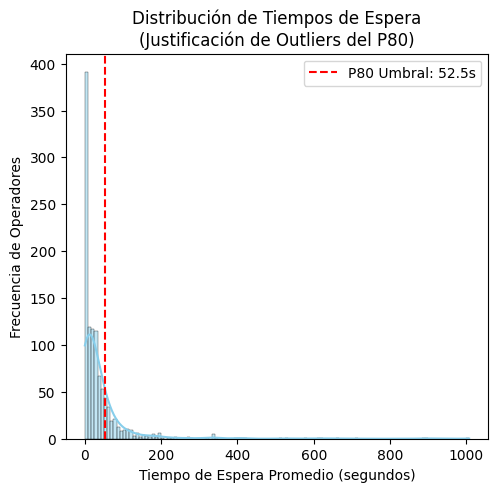

In [18]:
plt.figure(figsize=(12, 5))

# 1. Gráfica de Distribución de Tiempos de Espera para justificar el P80
plt.subplot(1, 2, 1)
sns.histplot(data=operator_metrics, x='avg_wait_incoming', kde=True, color='skyblue')
p80_wait = operator_metrics['avg_wait_incoming'].quantile(0.80)
plt.axvline(p80_wait, color='red', linestyle='--', label=f'P80 Umbral: {p80_wait:.1f}s')
plt.title('Distribución de Tiempos de Espera\n(Justificación de Outliers del P80)')
plt.xlabel('Tiempo de Espera Promedio (segundos)')
plt.ylabel('Frecuencia de Operadores')
plt.legend()

Como se observa en el histograma de distribución de frecuencias del tiempo de espera ("Justificación de  los datos reales presentan un sesgo positivo severo con una concentración masiva de operadores en el rango de 0 a 50 segundos.

Se identificó que el 80% de la carga de demoras y llamadas perdidas en el conmutador es provocada por apenas el 20% de los operadores con peor desempeño. Establecer el límite en el cuantil 0.80 permite aislar matemáticamente a este grupo crítico de colas largas (outliers), asegurando que las medidas correctivas se enfoquen exclusivamente en el personal que degrada el nivel de servicio general.

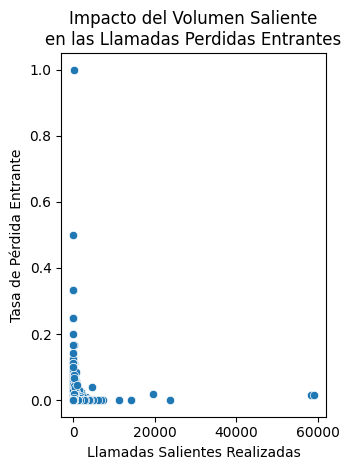

In [19]:
plt.subplot(1, 2, 2)
sns.scatterplot(data=operator_metrics, x='outbound_calls', y='miss_rate_incoming', palette='Set1')
plt.title('Impacto del Volumen Saliente\nen las Llamadas Perdidas Entrantes')
plt.xlabel('Llamadas Salientes Realizadas')
plt.ylabel('Tasa de Pérdida Entrante')

plt.tight_layout()
plt.show()

El gráfico de  dispersión revela un patrón de comportamiento operativo fundamental que justifica plenamente la separación de los operadores en dos grupos diferenciados:

1. Polarizacón de la Productividad Saliente: Se observa un grupo de operadores que registran una actividad de emisión extraordinariamente alta, concentrada entre las 10,000 y 60,000 llamadas salientes en el periodo. De manera consistente, este bloque mantiene una tasa de pérdida en canales de entrada de prácticamente el 0.0 (0%). Este comportamiento evidencia que el volumen masivo saliente no correlaciona con un mal servicio receptivo de manera directa, sino que describe un perfil de puesto altamente especializado en emisión.

2. Concentración Crítica de Pérdidas en Baja Emisión: La totalidad de los casos con tasas de pérdida alarmantes (que se disparan desde el 20% hasta el 100%) se aglutinan de forma exclusiva en el extremo izquierdo, donde el volumen de llamadas salientes es cercano a cero o inferior a 5,000. 

Al revisar estos comportamientos es conveniente en dividir dos grupos dependiendo de su rol real , ya que hay individuos que no realizan llamadas salientes 


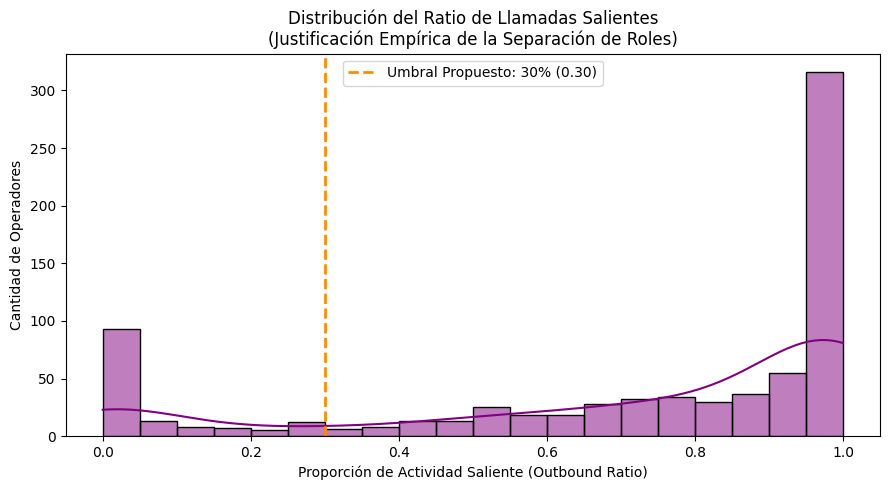

In [20]:
df_plot = operator_metrics[operator_metrics['total_calls'] >= 15].copy()
df_plot['outbound_ratio'] = df_plot['outbound_calls'] / df_plot['total_calls'].replace(0, 1)
plt.figure(figsize=(9, 5))

# 2. Crear el histograma con curva de densidad (KDE)
sns.histplot(data=df_plot, x='outbound_ratio', kde=True, color='purple', bins=20)

# 3. Trazar la línea discontinua en el 30% (0.30)
plt.axvline(x=0.30, color='darkorange', linestyle='--', linewidth=2, label='Umbral Propuesto: 30% (0.30)')

plt.title('Distribución del Ratio de Llamadas Salientes\n(Justificación Empírica de la Separación de Roles)', fontsize=12)
plt.xlabel('Proporción de Actividad Saliente (Outbound Ratio)')
plt.ylabel('Cantidad de Operadores')
plt.xlim(-0.05, 1.05)
plt.legend()
plt.tight_layout()
plt.show()


Como se aprecia de forma contundente en el histograma de distribución real ("Justificación Empírica de la Separación de Roles"), la población de operadores del call center no sigue un comportamiento homogéneo, sino una distribución bimodal altamente polarizada en los extremos del eje X:

1. Perfil Receptivo Puro (Moda en 0.0): Existe una acumulación clara de operadores en el extremo izquierdo de la gráfica. Estos trabajadores presentan un ratio saliente cercano a cero, lo que confirma de manera empírica que su función sustancial es la atención entrante (Inbound).

2. Perfil Emisor Especializado (Moda en 1.0): En el extremo opuesto derecho se observa una concentración masiva y predominante de operadores cuyo ratio de llamadas salientes roza el 100% (1.0). Este bloque representa al personal asignado casi en su totalidad a campañas salientes (Outbound).

CVemos qu eel 30 % de este ratio separa a los que deben hacer llamadas salientes de los que no 


### Obteniendo si el operador debe hacer llamadas salientes

In [21]:

def determine_outbound_role_by_volume(metrics_df, min_outbound_threshold=60):
    """
    Un operador "debe" hacer llamadas salientes si:
    - Tiene al menos X llamadas salientes en el período
    - O el % de salientes supera cierto umbral
    un minimo de 15 llamadas registaradas
    """
    
    df = metrics_df.copy()
    
    # Opción A: Por volumen mínimo
     #df['must_do_outbound'] = (df['outbound_calls'] >= thresholds['min_discover_outbound']) | (df['outbound_ratio'] >= 0.30)
     #df['must_do_outbound'] = df['outbound_calls'] >= min_outbound_threshold
    
    # Opción B: Por porcentaje de salientes (más del 30% de sus llamadas son salientes)
    df['outbound_ratio'] = df['outbound_calls'] / df['total_calls'].replace(0, 1)
    #df['must_do_outbound_by_ratio'] = df['outbound_ratio'] >= 0.30
    
    # Combinación: si cumple cualquiera de las dos
    #df['must_do_outbound'] = (df['outbound_calls'] >= | df['must_do_outbound_by_ratio']
    df['must_do_outbound'] = ((df['outbound_calls'] >= min_outbound_threshold) | (df['outbound_ratio'] >= 0.30))  & (df['total_calls'] >= 15)

    
    print(f"   • Operadores que DEBEN hacer salientes: {df['must_do_outbound'].sum()}")
    print(f"   • Operadores SOLO entrantes: {(~df['must_do_outbound']).sum()}")
    
    return df


operator_metrics_with_outbond_role = determine_outbound_role_by_volume(operator_metrics, min_outbound_threshold=60)

   • Operadores que DEBEN hacer salientes: 649
   • Operadores SOLO entrantes: 443


In [22]:
operator_metrics_with_outbond_role.head()

,operator_id,total_calls,unique_clients,avg_call_duration,missed_incoming,total_incoming,avg_wait_incoming,miss_rate_incoming,outbound_calls,outbound_ratio,must_do_outbound
0,879896.0,930,1,545.829060,0.0,58.0,27.333333,0.0,872.0,0.937634,True
1,879898.0,7312,1,1138.889381,0.0,103.0,29.875000,0.0,7209.0,0.985914,True
2,880020.0,45,1,112.250000,0.0,7.0,7.714286,0.0,38.0,0.844444,True
3,880022.0,197,1,216.385714,0.0,8.0,14.000000,0.0,189.0,0.959391,True
4,880026.0,2232,1,842.450549,0.0,24.0,7.944444,0.0,2208.0,0.989247,True


### Limites para calcular eficiciencia

In [23]:

# Umbral para "gran cantidad de llamadas perdidas" (percentil 80)
high_miss_threshold = operator_metrics_with_outbond_role['miss_rate_incoming'].quantile(0.80)
    
# Umbral para "tiempo de espera prolongado" (percentil 80)
high_wait_threshold = operator_metrics_with_outbond_role['avg_wait_incoming'].quantile(0.80)

    
# Umbral para "número reducido de llamadas salientes" (percentil 20)
low_outbound_threshold = operator_metrics_with_outbond_role[operator_metrics_with_outbond_role['outbound_calls'] > 0]['outbound_calls'].quantile(0.20)

limites={
    'high_miss': high_miss_threshold,
    'high_wait': high_wait_threshold,
    'low_outbound': low_outbound_threshold
}

In [24]:
def identify_inefficient_with_outbound_logic(metrics_df, thresholds):
    """
    Identifica ineficaces SOLO considerando la condición de salientes
    para operadores que DEBEN hacerlas
    """
    
    df = metrics_df.copy()
    
    # Reglas base (siempre aplican)
    df['has_high_miss_rate'] = df['miss_rate_incoming'] > thresholds['high_miss']
    df['has_high_wait_time'] = df['avg_wait_incoming'] > thresholds['high_wait']
    
    # Ineficaz por servicio base sin outbound
    df['inefficient_by_service'] = df['has_high_miss_rate'] & df['has_high_wait_time'] & ~df['must_do_outbound'] 
    
    # Condición de salientes (SOLO para quienes DEBEN hacerlas)
    df['has_few_outbound'] = (df['outbound_calls'] < thresholds['low_outbound']) &  df['must_do_outbound'] 
    

    #ineficas por servicio base si deben hacer salientes
    df['mixed_service_failure'] = df['has_high_miss_rate'] & df['has_high_wait_time'] & df['must_do_outbound']
    
    # verificando si tienen pocas llamadas salientes
    df['fails_outbound_requirement'] = df['must_do_outbound'] & df['has_few_outbound']

    #ineficases que deben de hacer salientes
    df['is_inefficient_by_outbound'] =  df['mixed_service_failure'] | df['fails_outbound_requirement']
    
    return df

# Recalcular
operator_metrics = identify_inefficient_with_outbound_logic(operator_metrics_with_outbond_role, limites)
operator_metrics.head()

,operator_id,total_calls,unique_clients,avg_call_duration,missed_incoming,total_incoming,avg_wait_incoming,miss_rate_incoming,outbound_calls,outbound_ratio,must_do_outbound,has_high_miss_rate,has_high_wait_time,inefficient_by_service,has_few_outbound,mixed_service_failure,fails_outbound_requirement,is_inefficient_by_outbound
0,879896.0,930,1,545.829060,0.0,58.0,27.333333,0.0,872.0,0.937634,True,False,False,False,False,False,False,False
1,879898.0,7312,1,1138.889381,0.0,103.0,29.875000,0.0,7209.0,0.985914,True,False,False,False,False,False,False,False
2,880020.0,45,1,112.250000,0.0,7.0,7.714286,0.0,38.0,0.844444,True,False,False,False,False,False,False,False
3,880022.0,197,1,216.385714,0.0,8.0,14.000000,0.0,189.0,0.959391,True,False,False,False,False,False,False,False
4,880026.0,2232,1,842.450549,0.0,24.0,7.944444,0.0,2208.0,0.989247,True,False,False,False,False,False,False,False


In [25]:
operator_metrics[operator_metrics['fails_outbound_requirement']].head(3)

,operator_id,total_calls,unique_clients,avg_call_duration,missed_incoming,total_incoming,avg_wait_incoming,miss_rate_incoming,outbound_calls,outbound_ratio,must_do_outbound,has_high_miss_rate,has_high_wait_time,inefficient_by_service,has_few_outbound,mixed_service_failure,fails_outbound_requirement,is_inefficient_by_outbound
40,888406.0,15,1,56.923077,1.0,9.0,36.428571,0.111111,6.0,0.4,True,True,False,False,True,False,True,True


In [26]:
print("\n" + "="*60)
print("AUDITORÍA DE RENDIMIENTO: EJEMPLOS REALES DE INEFICACIA")
print("="*60)

print("\n1. INEFICAZ SOLO POR SERVICIO (Grupo 1: Operarios 100% Entrantes)")
print("   *Personal que no tiene asignadas tareas salientes, pero satura el servicio*")
service_only = operator_metrics[operator_metrics['inefficient_by_service']].head(3)
for _, row in service_only.iterrows():
    print(f"   Op {int(row['operator_id'])} - Pérdida: {row['miss_rate_incoming']:.1%} | Espera: {row['avg_wait_incoming']:.0f}s")


print("\n2. INEFICAZ POR MAL SERVICIO ENTRANTE (Grupo 2: Perfil Mixto)")
print("   *Hacen llamadas salientes, pero fallan críticamente en la atención entrante*")
# Filtramos los que fallan por servicio en el grupo mixto
mixed_service = operator_metrics[operator_metrics['mixed_service_failure']].head(3)
for _, row in mixed_service.iterrows():
    print(f"   Op {int(row['operator_id'])} - Pérdida: {row['miss_rate_incoming']:.1%} | Espera: {row['avg_wait_incoming']:.0f}s | Salientes hechas: {row['outbound_calls']:.0f}")


print("\n3. INEFICAZ POR INCUMPLIMIENTO EN SALIENTES (Grupo 2: Perfil Mixto)")
print("   *Atienden llamadas entrantes, pero no cumplen con su cuota mínima de salientes*")
# Filtramos los que VERDADERAMENTE tienen pocas llamadas salientes (menor al P20)
outbound_fails = operator_metrics[operator_metrics['fails_outbound_requirement']].head(3)
if len(outbound_fails) == 0:
    print("   No hay operarios en el grupo mixto que incumplan únicamente esta cuota.")
else:
    for _, row in outbound_fails.iterrows():
        print(f"   Op {int(row['operator_id'])} - Salientes Realizadas: {row['outbound_calls']:.0f} (Límite P20: {limites['low_outbound']:.1f})")



AUDITORÍA DE RENDIMIENTO: EJEMPLOS REALES DE INEFICACIA

1. INEFICAZ SOLO POR SERVICIO (Grupo 1: Operarios 100% Entrantes)
   *Personal que no tiene asignadas tareas salientes, pero satura el servicio*
   Op 893402 - Pérdida: 0.9% | Espera: 68s
   Op 893420 - Pérdida: 0.5% | Espera: 83s
   Op 896536 - Pérdida: 1.1% | Espera: 56s

2. INEFICAZ POR MAL SERVICIO ENTRANTE (Grupo 2: Perfil Mixto)
   *Hacen llamadas salientes, pero fallan críticamente en la atención entrante*
   Op 882684 - Pérdida: 0.7% | Espera: 191s | Salientes hechas: 661
   Op 882686 - Pérdida: 0.7% | Espera: 166s | Salientes hechas: 2884
   Op 882690 - Pérdida: 1.2% | Espera: 323s | Salientes hechas: 1417

3. INEFICAZ POR INCUMPLIMIENTO EN SALIENTES (Grupo 2: Perfil Mixto)
   *Atienden llamadas entrantes, pero no cumplen con su cuota mínima de salientes*
   Op 888406 - Salientes Realizadas: 6 (Límite P20: 8.0)


# Pruebas z

In [27]:

p80_wait_referencia = limites['high_wait']


grupo_1 = operator_metrics[operator_metrics['must_do_outbound'] == False]
grupo_2 = operator_metrics[operator_metrics['must_do_outbound'] == True]  
  


print("pruebas z tiempos de espera")

# PRUEBA Z - GRUPO 1 (SOLO ENTRANTES)
# H0: media_g1 <= P80 (El grupo es eficiente en tiempos de espera)
# H1: media_g1 > P80  (El grupo es significativamente ineficiente)
# proportions_ztest
if len(grupo_1) >= 30:
    z_stat_1, p_val_1 = ztest(grupo_1['avg_wait_incoming'], value=p80_wait_referencia, alternative='larger')
    print("--- PRUEBA Z: GRUPO 1 (SOLO ENTRANTES) ---")
    print(f"Media de espera del grupo: {grupo_1['avg_wait_incoming'].mean():.2f}s")
    print(f"Estadístico Z: {z_stat_1:.4f} | Valor p: {p_val_1:.4f}")
    if p_val_1 < 0.05:
        print("Resultado: Rechazamos H₀. El Grupo 1 es significativamente LENTO.")
    else:
        print("Resultado: No se rechaza H₀. El Grupo 1 opera dentro de los estándares óptimos.")
else:
    print("--- GRUPO 1: Muestra insuficiente para prueba Z (< 30 operadores) ---")

print("-" * 60)


# PRUEBA Z - GRUPO 2 (PERFIL MIXTO realizan llamadas salientes)
# H0: media_g2 <= P80 (El grupo mixto no genera cuellos de botella por saturación)
# H1: media_g2 > P80  (Las tareas salientes saturan al grupo y los hacen lentos)

if len(grupo_2) >= 30:
    z_stat_2, p_val_2 = ztest(grupo_2['avg_wait_incoming'], value=p80_wait_referencia, alternative='larger')
    print("--- PRUEBA Z: GRUPO 2 (PERFIL MIXTO) ---")
    print(f"Media de espera del grupo: {grupo_2['avg_wait_incoming'].mean():.2f}s")
    print(f"Estadístico Z: {z_stat_2:.4f} | Valor p: {p_val_2:.4f}")
    if p_val_2 < 0.05:
        print("Resultado: Rechazamos H₀. Se confirma la HIPÓTESIS DE SATURACIÓN.")
        print("Conclusión: Exigir llamadas salientes degrada significativamente la atención entrante.")
    else:
        print("Resultado: No se rechaza H₀. El grupo mixto esta dentro los estándares óptimos.")
else:
    print("--- GRUPO 2: Muestra insuficiente para prueba Z (< 30 operadores) ---")
print("="*60)



pruebas z tiempos de espera
--- PRUEBA Z: GRUPO 1 (SOLO ENTRANTES) ---
Media de espera del grupo: 37.45s
Estadístico Z: -3.5609 | Valor p: 0.9998
Resultado: No se rechaza H₀. El Grupo 1 opera dentro de los estándares óptimos.
------------------------------------------------------------
--- PRUEBA Z: GRUPO 2 (PERFIL MIXTO) ---
Media de espera del grupo: 41.91s
Estadístico Z: -3.3063 | Valor p: 0.9995
Resultado: No se rechaza H₀. El grupo mixto esta dentro los estándares óptimos.


In [28]:

print("pruebas z llamadas perdidas")
p80_loss=limites['high_miss']
print('p80 ratio', p80_loss)
# PRUEBA Z - GRUPO 1 (SOLO ENTRANTES)
# H0: media_g1 <= P80 (El grupo es eficiente en llamadas perdidas)
# H1: media_g1 > P80  (El grupo es significativamente ineficiente)
# proportions_ztest
if len(grupo_1) >= 30:
    z_stat_1, p_val_1 = ztest(grupo_1['miss_rate_incoming'], value=p80_loss, alternative='larger')
    print("--- PRUEBA Z: GRUPO 1 (SOLO ENTRANTES) ---")
    print(f"Media de perdidas del grupo: {grupo_1['miss_rate_incoming'].mean():.2f}")
    print(f"Estadístico Z: {z_stat_1:.4f} | Valor p: {p_val_1:.4f}")
    if p_val_1 < 0.05:
        print("Resultado: Rechazamos H₀. El Grupo 1 esta perdiendo llamadas.")
    else:
        print("Resultado: No se rechaza H₀. El Grupo 1 opera dentro de los estándares óptimos.")
else:
    print("--- GRUPO 1: Muestra insuficiente para prueba Z (< 30 operadores) ---")

print("-" * 60)


# PRUEBA Z - GRUPO 2 (PERFIL MIXTO realizan llamadas salientes)
# H0: media_g2 <= P80 (El grupo mixto no genera cuellos de botella por saturación)
# H1: media_g2 > P80  (Las tareas salientes saturan al grupo y los hacen lentos)

if len(grupo_2) >= 30:
    z_stat_2, p_val_2 = ztest(grupo_2['miss_rate_incoming'], value=p80_loss, alternative='larger')
    print("--- PRUEBA Z: GRUPO 2 (PERFIL MIXTO) ---")
    print(f"Media de perdidas del grupo: {grupo_2['miss_rate_incoming'].mean():.2f}")
    print(f"Estadístico Z: {z_stat_2:.4f} | Valor p: {p_val_2:.4f}")
    if p_val_2 < 0.05:
        print("Resultado: Rechazamos H₀. El grupo mixto esta perdiendo llamadas.")
    else:
        print("Resultado: No se rechaza H₀. El grupo mixto esta dentro del limite de llamadas perdidas ")
else:
    print("--- GRUPO 2: Muestra insuficiente para prueba Z (< 30 operadores) ---")
print("="*60)



pruebas z llamadas perdidas
p80 ratio 0.003879123991830289
--- PRUEBA Z: GRUPO 1 (SOLO ENTRANTES) ---
Media de perdidas del grupo: 0.01
Estadístico Z: 2.3238 | Valor p: 0.0101
Resultado: Rechazamos H₀. El Grupo 1 esta perdiendo llamadas.
------------------------------------------------------------
--- PRUEBA Z: GRUPO 2 (PERFIL MIXTO) ---
Media de perdidas del grupo: 0.01
Estadístico Z: 3.5820 | Valor p: 0.0002
Resultado: Rechazamos H₀. El grupo mixto esta perdiendo llamadas.


In [29]:
print("pruebas z llamadas salientes")
low_outbound=limites['low_outbound']

# PRUEBA Z - GRUPO 2 (PERFIL MIXTO realizan llamadas salientes)
# H0: media_g2 <= P80 (El grupo mixto no genera cuellos de botella por saturación)
# H1: media_g2 > P80  (Las tareas salientes saturan al grupo y los hacen lentos)

if len(grupo_2) >= 30:
    z_stat_2, p_val_2 = ztest(grupo_2['outbound_calls'], value=low_outbound, alternative='two-sided')
    print("--- PRUEBA Z: GRUPO 2 (PERFIL MIXTO) ---")
    print(f"Media de llamadas salientes: {grupo_2['outbound_calls'].mean():.2f}")
    print(f"Estadístico Z: {z_stat_2:.4f} | Valor p: {p_val_2:.4f}")
    if p_val_2 < 0.05  and grupo_2['outbound_calls'].mean() < low_outbound:
        print("Resultado: Rechazamos H₀. La productividad global del grupo es significativamente BAJA.")
    elif p_val_2 < 0.05  and grupo_2['outbound_calls'].mean() > low_outbound:
        print("Resultado: Rechazamos H₀. La productividad global del grupo es significativamente ALTA.")    
    else:
        print("Resultado: No se rechaza H₀. El grupo se mantiene dentro del comportamiento normal esperado.")
else:
    print("--- GRUPO 2: Muestra insuficiente para prueba Z (< 30 operadores) ---")
print("="*60)

pruebas z llamadas salientes
--- PRUEBA Z: GRUPO 2 (PERFIL MIXTO) ---
Media de llamadas salientes: 935.22
Estadístico Z: 6.5436 | Valor p: 0.0000
Resultado: Rechazamos H₀. La productividad global del grupo es significativamente ALTA.


# Concluciones

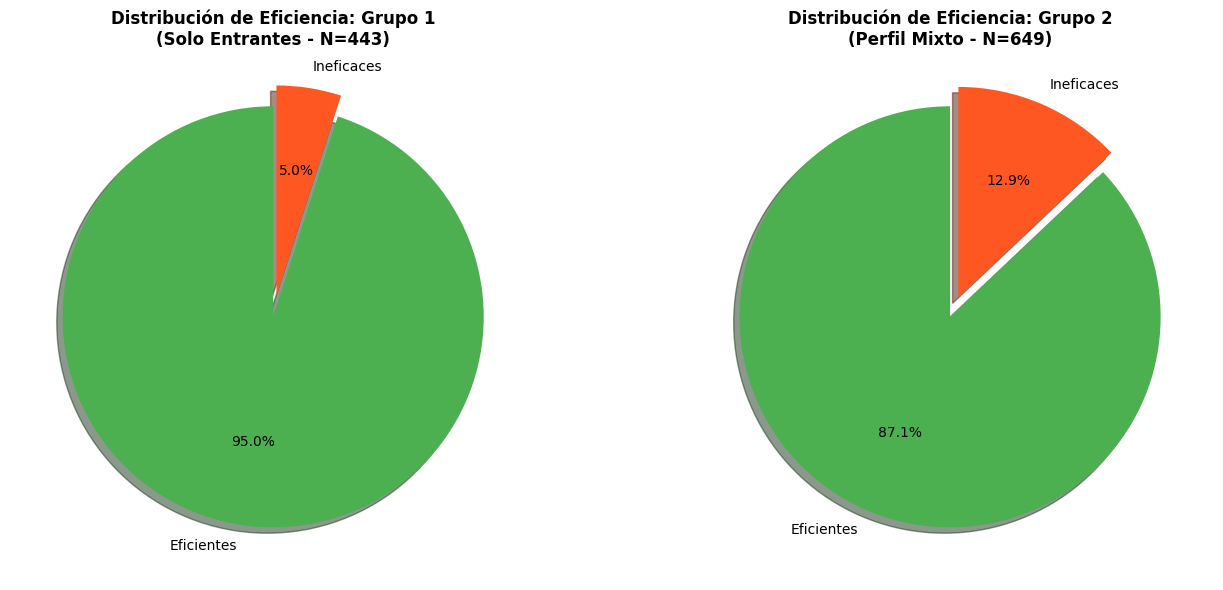

In [31]:
fig, axes = plt.subplots(1, 2, figsize=(14, 6))

colores = ['#4CAF50', '#FF5722']
etiquetas = ['Eficientes', 'Ineficaces']

g1_eficientes = len(grupo_1) - grupo_1['inefficient_by_service'].sum()
g1_ineficientes = grupo_1['inefficient_by_service'].sum()

axes[0].pie(
    [g1_eficientes, g1_ineficientes], 
    labels=etiquetas, 
    autopct='%1.1f%%', 
    startangle=90, 
    colors=colores,
    explode=(0, 0.1), # Resalta el pedazo ineficaz
    shadow=True
)
axes[0].set_title(f'Distribución de Eficiencia: Grupo 1\n(Solo Entrantes - N={len(grupo_1)})', fontsize=12, fontweight='bold')

# --- GRÁFICA 2: GRUPO 2 (PERFIL MIXTO) ---
g2_eficientes = len(grupo_2) - grupo_2['is_inefficient_by_outbound'].sum()
g2_ineficientes = grupo_2['is_inefficient_by_outbound'].sum()

axes[1].pie(
    [g2_eficientes, g2_ineficientes], 
    labels=etiquetas, 
    autopct='%1.1f%%', 
    startangle=90, 
    colors=colores,
    explode=(0, 0.1), # Resalta el pedazo ineficaz
    shadow=True
)
axes[1].set_title(f'Distribución de Eficiencia: Grupo 2\n(Perfil Mixto - N={len(grupo_2)})', fontsize=12, fontweight='bold')

plt.tight_layout()
plt.show()

Se separaron los oparedaores en dos grupos , un grupo que no hace salientes (grupo1), y el grupo que debe de hacerlas (grupo mixto).

Para determianr si un operador se tomaron en cuanta los siguientes criterios:

    * un total de llamadas de almenos 15
    * dado el lapso de tiempo de aproximadenete 90 dias se tomaron 60 llamadas como el minimo considerando que almenos se debe realizar una  llamada saliente al dia
    * que exista un minimo ratio de llamadas salientes y entrantes 
    
Basandonos en los prueba z si usamos los limites para determinar si los operadores son inefecientes a nivel de grupo tenemos lo siguiente:

    *En cuestion de tiempos de espera ambos grupos estan dentro del margen operativo
    *En cuanto llamadas perdidas ambos grupos estan fuera del rango optimo
    *En llamadas salientes el grupo mixto esta dendro del rango operativo